# Sentiment Analysis with RNN, LSTM and GRU

In [1]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, SimpleRNN, LSTM, GRU, RepeatVector
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

os.makedirs('plots', exist_ok=True)


# Task 1: Text Loading, Cleaning, Tokenisation & Padding

## 1.1 Load and inspect
Download `IMDB Dataset.csv` from https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews and keep it in the same folder as this notebook.

In [2]:
df = pd.read_csv('IMDB Dataset.csv')
print(df.shape)
print(df.head())
print(df['sentiment'].value_counts())
print(df.isnull().sum())

print('--- raw review 1 ---')
print(df['review'][0])
print('--- raw review 2 ---')
print(df['review'][1])

(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
review       0
sentiment    0
dtype: int64
--- raw review 1 ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<b

## 1.2 Remove duplicates

In [3]:
print('duplicates:', df.duplicated().sum())
rows_before = df.shape[0]
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print('rows before:', rows_before, '| rows after:', df.shape[0])

duplicates: 418
rows before: 50000 | rows after: 49582


## 1.3 Clean the text

In [4]:
def clean_text(s):
    s = s.lower()
    s = re.sub(r'<.*?>', ' ', s)            # remove HTML tags
    s = re.sub(r"[^a-z' ]", ' ', s)         # keep only letters, apostrophes and spaces
    s = re.sub(r'\s+', ' ', s).strip()      # collapse repeated spaces
    return s

print('BEFORE:', df['review'][0][:300])
df['clean'] = df['review'].apply(clean_text)
print('AFTER :', df['clean'][0][:300])

BEFORE: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru
AFTER : one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not 


## 1.4 Review length analysis

mean: 230.0 | median: 172.0 | 90th: 449.0 | 95th: 587.0 | max: 2462


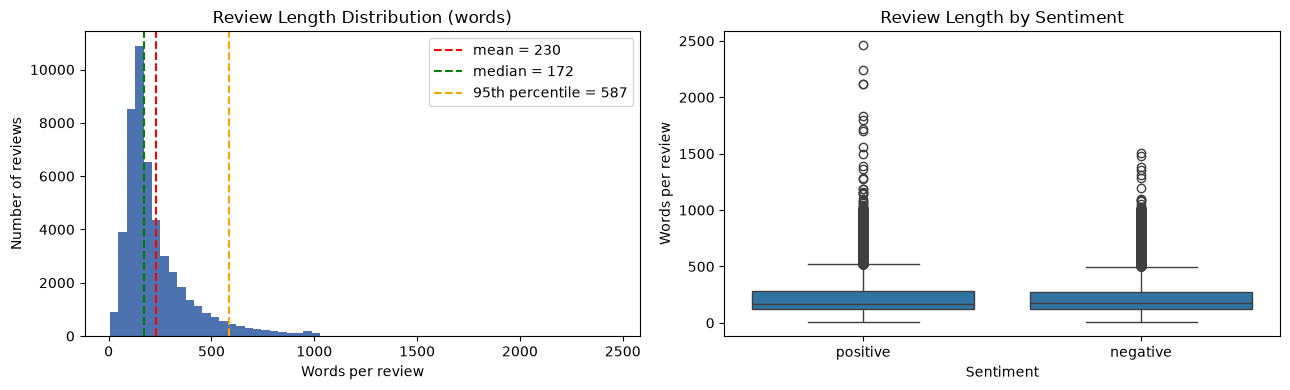

In [5]:
df['label'] = (df['sentiment'] == 'positive').astype(int)
df['words'] = df['clean'].apply(lambda s: len(s.split()))

mean_len = df['words'].mean()
median_len = df['words'].median()
p90 = np.percentile(df['words'], 90)
p95 = np.percentile(df['words'], 95)
print('mean:', round(mean_len, 1), '| median:', median_len, '| 90th:', p90, '| 95th:', p95, '| max:', df['words'].max())

plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.hist(df['words'], bins=60, color='#4c72b0')
plt.axvline(mean_len, color='red', linestyle='--', label='mean = ' + str(round(mean_len)))
plt.axvline(median_len, color='green', linestyle='--', label='median = ' + str(round(median_len)))
plt.axvline(p95, color='orange', linestyle='--', label='95th percentile = ' + str(round(p95)))
plt.title('Review Length Distribution (words)')
plt.xlabel('Words per review')
plt.ylabel('Number of reviews')
plt.legend()

plt.subplot(1, 2, 2)
sns.boxplot(x='sentiment', y='words', data=df)
plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Words per review')
plt.tight_layout()
plt.savefig('plots/length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# padding length: roughly the 90th-95th percentile, rounded
MAXLEN = int(round((p90 + p95) / 2, -1))
print('MAXLEN =', MAXLEN)

MAXLEN = 520


## 1.5 and 1.6 Split, tokenise, pad
The split is done on the cleaned text **before** the tokenizer is fitted, and the tokenizer is fitted on the TRAINING texts only.

In [7]:
X_train_text, X_test_text, y_train, y_test = train_test_split(df['clean'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])
X_train_text = X_train_text.tolist()
X_test_text = X_test_text.tolist()
y_train = y_train.values
y_test = y_test.values
print(len(X_train_text), len(X_test_text))

tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)       # training texts only

train_seq = tokenizer.texts_to_sequences(X_train_text)
test_seq = tokenizer.texts_to_sequences(X_test_text)

print('10 most frequent words:', list(tokenizer.word_index.items())[:10])
print('review as text    :', X_train_text[0][:150])
print('review as integers:', train_seq[0][:25])

39665 9917
10 most frequent words: [('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10)]
review as text    : i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to bl
review as integers: [10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35]


In [8]:
X_train = pad_sequences(train_seq, maxlen=MAXLEN, padding='pre', truncating='pre')
X_test = pad_sequences(test_seq, maxlen=MAXLEN, padding='pre', truncating='pre')

print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_test :', X_test.shape, '| y_test :', y_test.shape)
print(X_train[0][-20:])

X_train: (39665, 520) | y_train: (39665,)
X_test : (9917, 520) | y_test : (9917,)
[  22  206    1   35  547    7   21   32 5465 2566 1390   22   15   11
   16    3 3499  784   20    9]


## 1.7 Why this data is sequential

In [9]:
class EpochTimer(Callback):
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.start)


def build_model(cell_type, units=64, maxlen=None, emb_dim=32, lr=0.001, clipnorm=None):
    if maxlen is None:
        maxlen = MAXLEN
    keras.utils.set_random_seed(42)            # same start for every experiment
    model = Sequential()
    model.add(Input(shape=(maxlen,)))
    model.add(Embedding(10000, emb_dim))
    if cell_type == 'rnn':
        model.add(SimpleRNN(units))
    elif cell_type == 'lstm':
        model.add(LSTM(units))
    elif cell_type == 'gru':
        model.add(GRU(units))
    elif cell_type == 'stacked_lstm':
        model.add(LSTM(units, return_sequences=True))
        model.add(LSTM(32))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(learning_rate=lr, clipnorm=clipnorm), loss='binary_crossentropy', metrics=['accuracy'])
    return model


results = {}
models = {}

def evaluate_model(name, model, history, timer, X_te=None):
    if X_te is None:
        X_te = X_test
    prob = model.predict(X_te, verbose=0).flatten()
    pred = (prob > 0.5).astype(int)
    results[name] = {
        'Parameters': model.count_params(),
        'Time per Epoch (s)': round(float(np.mean(timer.times)), 1),
        'Epochs Trained': len(history.history['loss']),
        'Test Accuracy': round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall': round(recall_score(y_test, pred), 4),
        'F1': round(f1_score(y_test, pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, prob), 4),
        'prob': prob
    }
    models[name] = model
    print(name, '->', {k: v for k, v in results[name].items() if k != 'prob'})
    return prob, pred

# Task 2: RNN Intuition, RNN vs ANN & Forward Propagation

## 2.1 Baseline ANN on text (order-blind)

In [10]:
model_ann = Sequential()
model_ann.add(Input(shape=(MAXLEN,)))
model_ann.add(Embedding(10000, 32))
model_ann.add(Flatten())
model_ann.add(Dense(64, activation='relu'))
model_ann.add(Dense(1, activation='sigmoid'))
model_ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_ann.summary()

keras.utils.set_random_seed(42)
timer_ann = EpochTimer()
history_ann = model_ann.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, callbacks=[timer_ann], verbose=1)
prob_ann, pred_ann = evaluate_model('ANN baseline', model_ann, history_ann, timer_ann)
print('ANN parameter count:', model_ann.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 520, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16640)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,065,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,385,089 (5.28 MB)

 Trainable params: 1,385,089 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8105 - loss: 0.3907 - val_accuracy: 0.8856 - val_loss: 0.2861
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9483 - loss: 0.1418 - val_accuracy: 0.8661 - val_loss: 0.3819
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9880 - loss: 0.0381 - val_accuracy: 0.8551 - val_loss: 0.5257
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9974 - loss: 0.0102 - val_accuracy: 0.8551 - val_loss: 0.6048
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9999 - loss: 0.0014 - val_accuracy: 0.8578 - val_loss: 0.6555
ANN baseline -> {'Parameters': 1385089, 'Time per Epoch (s)': 7.4, 'Epochs Trained': 5, 'Test Accuracy': 0.8629, 'Precision': 0.8645, 'Recall': 0.8618, 'F1': 0.8632, 'ROC-AUC': 0.9358}
ANN parameter count: 1385089


## 2.3 Manual forward propagation in NumPy

h(1) = [-0.3876 -0.9541  0.4043]
h(2) = [-0.5841 -0.1799  0.4847]
h(3) = [-6.695e-01 -9.467e-01 -6.000e-04]
h(4) = [-0.8657 -0.5083  0.7751]


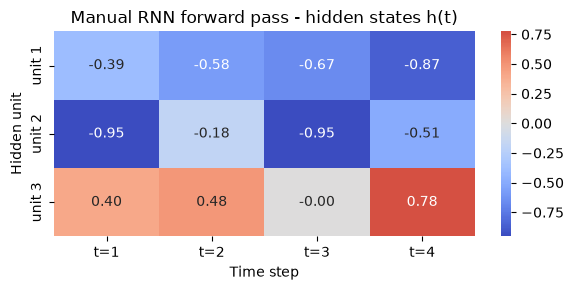

In [11]:
np.random.seed(42)
Wxh = np.random.randn(3, 2) * 0.5
Whh = np.random.randn(3, 3) * 0.5
b = np.random.randn(3) * 0.5

x_seq = np.random.randn(4, 2)          # 4 time steps, 2 input features

h = np.zeros(3)                         # h(0) = 0
H_manual = []
for t in range(4):
    h = np.tanh(Wxh @ x_seq[t] + Whh @ h + b)
    H_manual.append(h)
    print('h(' + str(t + 1) + ') =', np.round(h, 4))
H_manual = np.array(H_manual)           # shape (4, 3)

plt.figure(figsize=(6, 3))
sns.heatmap(H_manual.T, annot=True, fmt='.2f', cmap='coolwarm', center=0, xticklabels=['t=1', 't=2', 't=3', 't=4'], yticklabels=['unit 1', 'unit 2', 'unit 3'])
plt.title('Manual RNN forward pass - hidden states h(t)')
plt.xlabel('Time step')
plt.ylabel('Hidden unit')
plt.tight_layout()
plt.savefig('plots/rnn_forward_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.4 Verify against Keras

In [12]:
layer = SimpleRNN(3, return_sequences=True, use_bias=True)
layer.build((None, 4, 2))
layer.set_weights([Wxh.T, Whh.T, b])      # Keras stores kernels as (input, units)

H_keras = layer(x_seq.reshape(1, 4, 2)).numpy()[0]
print(np.round(H_keras, 4))
print('same as manual:', np.allclose(H_keras, H_manual, atol=1e-5))

[[-3.876e-01 -9.541e-01  4.043e-01]
 [-5.841e-01 -1.799e-01  4.847e-01]
 [-6.695e-01 -9.467e-01 -6.000e-04]
 [-8.657e-01 -5.083e-01  7.751e-01]]
same as manual: True


## 2.5 Parameter count by formula

In [13]:
units = 64
emb_dim = 32
formula_count = units * (emb_dim + units + 1)
print('formula: units x (embedding_dim + units + 1) =', units, 'x (', emb_dim, '+', units, '+ 1 ) =', formula_count)

test_layer = SimpleRNN(64)
test_layer.build((None, MAXLEN, 32))
print('Keras SimpleRNN(64) parameters:', test_layer.count_params())

formula: units x (embedding_dim + units + 1) = 64 x ( 32 + 64 + 1 ) = 6208
Keras SimpleRNN(64) parameters: 6208


## 2.6 RNN vs ANN summary

| Property | ANN (Flatten + Dense) | RNN |
|---|---|---|
| Input handling | Fixed-size vector; every position is a separate input | One element at a time, any length (fixed weights) |
| Word-order awareness | None (each slot is independent; the order is only encoded by position-specific weights) | Yes — the hidden state depends on the order of the inputs |
| Weight sharing | No | Yes, the same weights at every time step |
| Parameters vs sequence length | Grow with `MAXLEN` | Independent of `MAXLEN` |
| Memory of earlier words | None | Hidden state `h(t)` (short-term, fades over long distances) |
| Typical use cases | Tabular data, fixed-size features | Text, speech, time series |

# Task 3: Types of RNN & Sentiment Analysis with SimpleRNN

## 3.1 Types of RNN — shape demonstration

In [14]:
dummy = np.random.randn(4, 10, 8).astype('float32')      # batch 4, 10 time steps, 8 features

# (a) one-to-one: ordinary ANN on a single vector
m_a = Sequential()
m_a.add(Input(shape=(8,)))
m_a.add(Dense(1))
out_a = m_a(dummy[:, 0, :])

# (b) one-to-many: one vector -> repeated 10 times -> RNN gives a sequence
m_b = Sequential()
m_b.add(Input(shape=(8,)))
m_b.add(RepeatVector(10))
m_b.add(SimpleRNN(16, return_sequences=True))
out_b = m_b(dummy[:, 0, :])

# (c) many-to-one: sequence in, last output only
m_c = Sequential()
m_c.add(Input(shape=(10, 8)))
m_c.add(SimpleRNN(16, return_sequences=False))
out_c = m_c(dummy)

# (d) many-to-many: sequence in, sequence out
m_d = Sequential()
m_d.add(Input(shape=(10, 8)))
m_d.add(SimpleRNN(16, return_sequences=True))
out_d = m_d(dummy)

print('(a) one-to-one  :', out_a.shape)
print('(b) one-to-many :', out_b.shape)
print('(c) many-to-one :', out_c.shape)
print('(d) many-to-many:', out_d.shape)

(a) one-to-one  : (4, 1)
(b) one-to-many : (4, 10, 16)
(c) many-to-one : (4, 16)
(d) many-to-many: (4, 10, 16)


| Type | Input shape | Output shape | `return_sequences` | Example application |
|---|---|---|---|---|
| One-to-One | (4, 8) | (4, 1) | — (plain Dense) | Image / tabular classification with an ordinary ANN |
| One-to-Many | (4, 8) | (4, 10, 16) | True | Image captioning (one image → a sentence) |
| Many-to-One | (4, 10, 8) | (4, 16) | False | **Sentiment analysis** (a whole review → one label) |
| Many-to-Many | (4, 10, 8) | (4, 10, 16) | True | Named-entity tagging, machine translation |

## 3.3 Build the SimpleRNN sentiment model

In [15]:
model_rnn = build_model('rnn', units=64)
model_rnn.summary()

rnn_layer_params = model_rnn.layers[1].count_params()
print('SimpleRNN layer parameters (Keras)  :', rnn_layer_params)
print('formula 64 x (32 + 64 + 1)          :', 64 * (32 + 64 + 1))

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 520, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

SimpleRNN layer parameters (Keras)  : 6208
formula 64 x (32 + 64 + 1)          : 6208


## 3.4 Train and plot

In [16]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
timer_rnn = EpochTimer()
history_rnn = model_rnn.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.1, callbacks=[early_stop, timer_rnn], verbose=1)
print('time per epoch (s):', [round(t, 1) for t in timer_rnn.times])

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 48s 82ms/step - accuracy: 0.6238 - loss: 0.6328 - val_accuracy: 0.7298 - val_loss: 0.5535
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.7453 - loss: 0.5339 - val_accuracy: 0.6443 - val_loss: 0.6331
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 47s 84ms/step - accuracy: 0.6569 - loss: 0.6265 - val_accuracy: 0.6882 - val_loss: 0.5780
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 49s 87ms/step - accuracy: 0.7599 - loss: 0.5023 - val_accuracy: 0.7777 - val_loss: 0.4891
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 61s 110ms/step - accuracy: 0.7736 - loss: 0.4765 - val_accuracy: 0.8016 - val_loss: 0.5094
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 72s 129ms/step - accuracy: 0.7523 - loss: 0.5145 - val_accuracy: 0.7421 - val_loss: 0.5459
Epoch 7/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 51s 92ms/step - accuracy: 0.7660 - loss: 0.4864 - val_accuracy: 0.7847 - val_loss: 0.4836
Epoch 8/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 44s 79ms/step - accuracy: 0.6678 - loss: 0.6030 

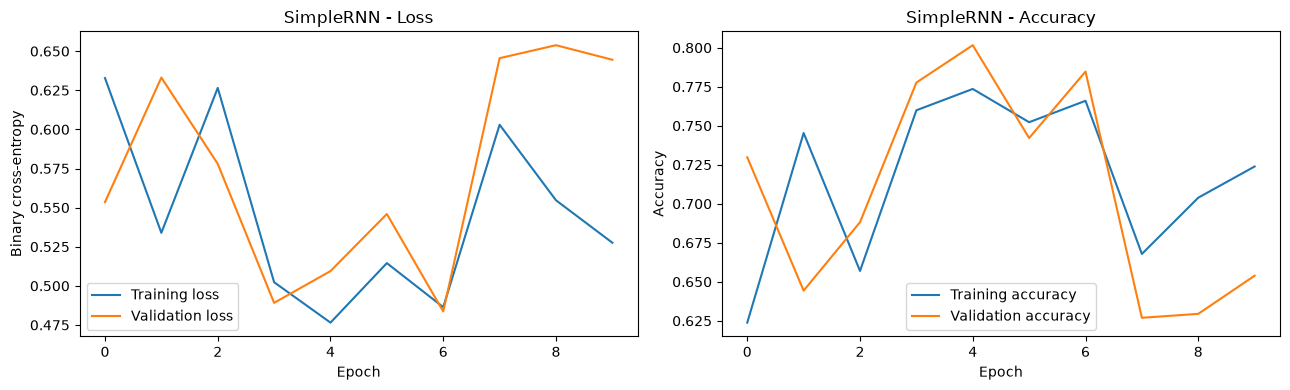

In [17]:
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(history_rnn.history['loss'], label='Training loss')
plt.plot(history_rnn.history['val_loss'], label='Validation loss')
plt.title('SimpleRNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_rnn.history['accuracy'], label='Training accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Validation accuracy')
plt.title('SimpleRNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.savefig('plots/training_curves_simplernn.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.5 Evaluate

SimpleRNN -> {'Parameters': 326273, 'Time per Epoch (s)': 47.4, 'Epochs Trained': 10, 'Test Accuracy': 0.795, 'Precision': 0.7868, 'Recall': 0.8113, 'F1': 0.7989, 'ROC-AUC': 0.8661}
              precision    recall  f1-score   support

    negative       0.80      0.78      0.79      4940
    positive       0.79      0.81      0.80      4977

    accuracy                           0.79      9917
   macro avg       0.80      0.79      0.79      9917
weighted avg       0.80      0.79      0.79      9917



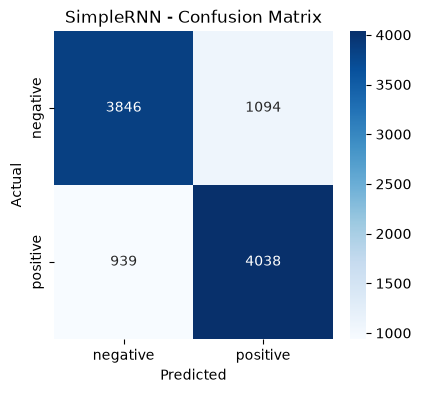

ROC-AUC: 0.8661


In [18]:
prob_rnn, pred_rnn = evaluate_model('SimpleRNN', model_rnn, history_rnn, timer_rnn)
print(classification_report(y_test, pred_rnn, target_names=['negative', 'positive']))

cm = confusion_matrix(y_test, pred_rnn)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.title('SimpleRNN - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
print('ROC-AUC:', results['SimpleRNN']['ROC-AUC'])

## 3.6 Embedding layer

In [19]:
emb_weights = model_rnn.layers[0].get_weights()[0]
print('embedding weight shape:', emb_weights.shape)

for word in ['good', 'bad']:
    idx = tokenizer.word_index[word]
    print(word, '(id', idx, ') ->', np.round(emb_weights[idx][:8], 3), '...')

v_good = emb_weights[tokenizer.word_index['good']]
v_bad = emb_weights[tokenizer.word_index['bad']]
print('cosine similarity good vs bad:', round(float(np.dot(v_good, v_bad) / (np.linalg.norm(v_good) * np.linalg.norm(v_bad))), 3))

embedding weight shape: (10000, 32)
good (id 49 ) -> [ 0.002 -0.12  -0.145 -0.128 -0.001 -0.058 -0.042  0.013] ...
bad (id 74 ) -> [ 0.038  0.199  0.174  0.023  0.111  0.121  0.285 -0.204] ...
cosine similarity good vs bad: -0.813


# Task 4: Backpropagation Through Time & Problems with RNN


## 4.3 Measure gradient flow with GradientTape

unrolled matches layer output: True
gradient norm at first step : 0.0
gradient norm at last step  : 0.007991096004843712


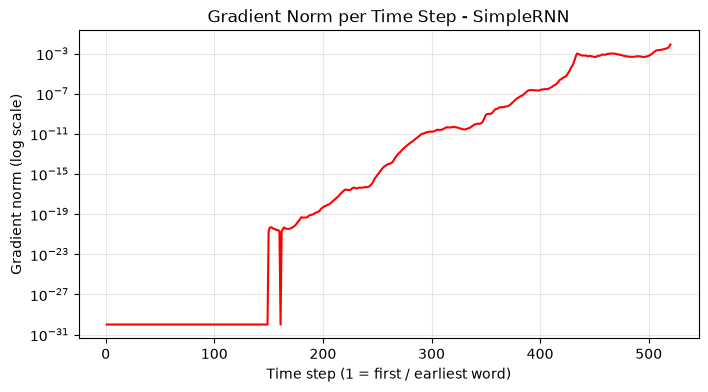

In [20]:
def gradient_norms(model, X_batch, y_batch):
    emb = model.layers[0]
    rnn = model.layers[1]
    out_layer = model.layers[-1]
    xb = tf.constant(X_batch)
    yb = tf.constant(y_batch.reshape(-1, 1).astype('float32'))
    with tf.GradientTape() as tape:
        x = emb(xb)                                              # (batch, T, emb)
        states = [tf.zeros((x.shape[0], rnn.units))] * (2 if isinstance(rnn, LSTM) else 1)
        H = []
        for t in range(x.shape[1]):
            h_t, states = rnn.cell(x[:, t, :], states)
            H.append(h_t)
        pred = out_layer(H[-1])
        loss = tf.reduce_mean(keras.losses.binary_crossentropy(yb, pred))
    grads = tape.gradient(loss, H)                                # one gradient per time step
    norms = [float(tf.reduce_mean(tf.norm(g, axis=-1))) for g in grads]
    # check: unrolled last hidden state equals the layer output
    same = np.allclose(H[-1].numpy(), rnn(emb(xb)).numpy(), atol=1e-4)
    return np.array(norms), same

X_batch = X_train[:64]
y_batch = y_train[:64]
gn_rnn, ok = gradient_norms(model_rnn, X_batch, y_batch)
print('unrolled matches layer output:', ok)
print('gradient norm at first step :', gn_rnn[0])
print('gradient norm at last step  :', gn_rnn[-1])

plt.figure(figsize=(8, 4))
plt.semilogy(range(1, MAXLEN + 1), gn_rnn + 1e-30, color='red')
plt.title('Gradient Norm per Time Step - SimpleRNN')
plt.xlabel('Time step (1 = first / earliest word)')
plt.ylabel('Gradient norm (log scale)')
plt.grid(True, alpha=0.3)
plt.savefig('plots/gradient_norm_simplernn.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.4 Accuracy vs sequence length

maxlen 50 -> test accuracy 0.7463
maxlen 100 -> test accuracy 0.7987
maxlen 200 -> test accuracy 0.7313
maxlen 300 -> test accuracy 0.733


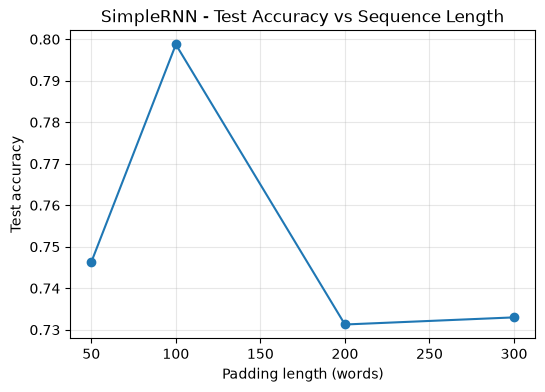

In [21]:
lengths = [50, 100, 200, 300]
acc_by_len = []
for L in lengths:
    Xtr = pad_sequences(train_seq, maxlen=L, padding='pre', truncating='pre')
    Xte = pad_sequences(test_seq, maxlen=L, padding='pre', truncating='pre')
    m = build_model('rnn', units=64, maxlen=L)
    m.fit(Xtr, y_train, epochs=8, batch_size=64, validation_split=0.1, verbose=0)
    loss, acc = m.evaluate(Xte, y_test, verbose=0)
    acc_by_len.append(acc)
    print('maxlen', L, '-> test accuracy', round(acc, 4))

plt.figure(figsize=(6, 4))
plt.plot(lengths, acc_by_len, marker='o')
plt.title('SimpleRNN - Test Accuracy vs Sequence Length')
plt.xlabel('Padding length (words)')
plt.ylabel('Test accuracy')
plt.grid(True, alpha=0.3)
plt.savefig('plots/simplernn_accuracy_vs_length.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.5 Exploding gradient demo and clipping

no clipping loss  : [0.6987 0.6541 0.6339 0.6116 0.6031]
clipnorm=1.0 loss : [0.7086    nan    nan    nan    nan]


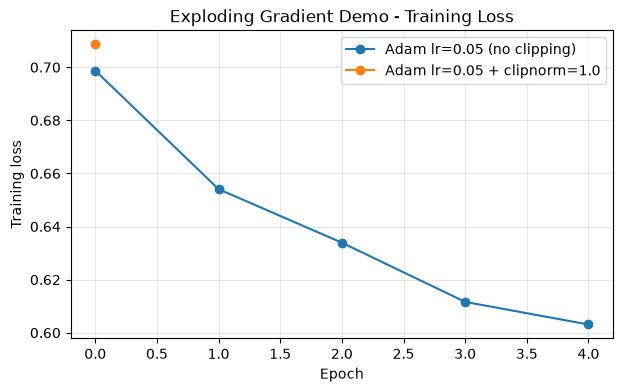

In [23]:
m_big = build_model('rnn', units=64, lr=0.05)
h_big = m_big.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=0)

m_clip = build_model('rnn', units=64, lr=0.05, clipnorm=1.0)
h_clip = m_clip.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=0)

print('no clipping loss  :', np.round(h_big.history['loss'], 4))
print('clipnorm=1.0 loss :', np.round(h_clip.history['loss'], 4))

plt.figure(figsize=(7, 4))
plt.plot(h_big.history['loss'], marker='o', label='Adam lr=0.05 (no clipping)')
plt.plot(h_clip.history['loss'], marker='o', label='Adam lr=0.05 + clipnorm=1.0')
plt.title('Exploding Gradient Demo - Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('plots/exploding_gradient_clipping.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.6 Problems summary

| Problem | Cause | Symptom observed in this notebook | Remedy |
|---|---|---|---|
| Vanishing gradient | Product of many factors < 1 (tanh derivative, small `W_hh`) | Gradient norm per time step drops by orders of magnitude (4.3); SimpleRNN accuracy near chance for several epochs / no gain from longer sequences (3.4, 4.4) | LSTM / GRU gating |
| Exploding gradient | Product of many factors > 1 (large `W_hh` or learning rate) | Loss spikes or NaN with a large learning rate (4.5) | Gradient clipping (`clipnorm`) |
| Slow sequential training | Each step needs the previous hidden state, so steps cannot run in parallel | Long time per epoch on long sequences (see time per epoch) | Shorter sequences, GPU |
| Short-term memory only | Early information fades through repeated multiplication | Accuracy does not improve with longer inputs (4.4) | Gated cells |

# Task 5: LSTM — Long Short-Term Memory

## 5.3 Parameter count by formula

In [24]:
lstm_formula = 4 * 64 * (32 + 64 + 1)
print('formula 4 x units x (embedding_dim + units + 1) = 4 x 64 x 97 =', lstm_formula)
test_lstm = LSTM(64)
test_lstm.build((None, MAXLEN, 32))
print('Keras LSTM(64) parameters:', test_lstm.count_params())
print('ratio to SimpleRNN:', test_lstm.count_params() / (64 * (32 + 64 + 1)))

formula 4 x units x (embedding_dim + units + 1) = 4 x 64 x 97 = 24832
Keras LSTM(64) parameters: 24832
ratio to SimpleRNN: 4.0


## 5.4 Manual single-step LSTM in NumPy

In [25]:
np.random.seed(42)
hidden = 3
inputs = 2
sigmoid = lambda z: 1 / (1 + np.exp(-z))

Wf = np.random.randn(hidden, hidden + inputs) * 0.5
Wi = np.random.randn(hidden, hidden + inputs) * 0.5
Wg = np.random.randn(hidden, hidden + inputs) * 0.5
Wo = np.random.randn(hidden, hidden + inputs) * 0.5
bf = np.random.randn(hidden) * 0.5
bi = np.random.randn(hidden) * 0.5
bg = np.random.randn(hidden) * 0.5
bo = np.random.randn(hidden) * 0.5

x_lstm = np.random.randn(4, inputs)
h = np.zeros(hidden)
C = np.zeros(hidden)

rows = []
for t in range(4):
    concat = np.concatenate([h, x_lstm[t]])
    f = sigmoid(Wf @ concat + bf)
    i = sigmoid(Wi @ concat + bi)
    g = np.tanh(Wg @ concat + bg)
    o = sigmoid(Wo @ concat + bo)
    C = f * C + i * g
    h = o * np.tanh(C)
    rows.append([t + 1, np.round(f, 3), np.round(i, 3), np.round(o, 3), np.round(C, 3), np.round(h, 3)])

lstm_table = pd.DataFrame(rows, columns=['t', 'f(t)', 'i(t)', 'o(t)', 'C(t)', 'h(t)'])
print(lstm_table.to_string(index=False))

 t                  f(t)                  i(t)                  o(t)                   C(t)                   h(t)
 1 [0.389, 0.584, 0.134] [0.156, 0.501, 0.613] [0.153, 0.726, 0.821] [0.087, 0.296, -0.459] [0.013, 0.209, -0.353]
 2 [0.079, 0.684, 0.759] [0.462, 0.883, 0.761]   [0.15, 0.471, 0.67]  [0.447, 1.078, -0.34]  [0.063, 0.373, -0.22]
 3 [0.445, 0.502, 0.376] [0.339, 0.604, 0.609] [0.433, 0.516, 0.633]  [0.241, 0.879, 0.132]  [0.102, 0.364, 0.083]
 4 [0.523, 0.414, 0.726]  [0.637, 0.715, 0.68]  [0.797, 0.29, 0.425] [-0.214, 0.463, 0.732] [-0.168, 0.125, 0.265]


## 5.5 Build, train and evaluate the LSTM
Same optimiser, batch size and epochs as Task 3.4 so the comparison is fair.

In [26]:
model_lstm = build_model('lstm', units=64)
model_lstm.summary()

timer_lstm = EpochTimer()
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history_lstm = model_lstm.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.1, callbacks=[early_stop, timer_lstm], verbose=1)
prob_lstm, pred_lstm = evaluate_model('LSTM', model_lstm, history_lstm, timer_lstm)
print(classification_report(y_test, pred_lstm, target_names=['negative', 'positive']))

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)        │ (None, 520, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 71s 125ms/step - accuracy: 0.8054 - loss: 0.4149 - val_accuracy: 0.8062 - val_loss: 0.4241
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 70s 125ms/step - accuracy: 0.8894 - loss: 0.2773 - val_accuracy: 0.8881 - val_loss: 0.2802
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 70s 125ms/step - accuracy: 0.9151 - loss: 0.2236 - val_accuracy: 0.8924 - val_loss: 0.2948
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 70s 125ms/step - accuracy: 0.9257 - loss: 0.1988 - val_accuracy: 0.8828 - val_loss: 0.3424
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 70s 125ms/step - accuracy: 0.9226 - loss: 0.2021 - val_accuracy: 0.8747 - val_loss: 0.3560
LSTM -> {'Parameters': 344897, 'Time per Epoch (s)': 70.0, 'Epochs Trained': 5, 'Test Accuracy': 0.8875, 'Precision': 0.8741, 'Recall': 0.9064, 'F1': 0.8899, 'ROC-AUC': 0.952}
              precision    recall  f1-score   support

    negative       0.90      0.87      0.88      4940
    positive       0.87      0.91      0.89      4977

    a

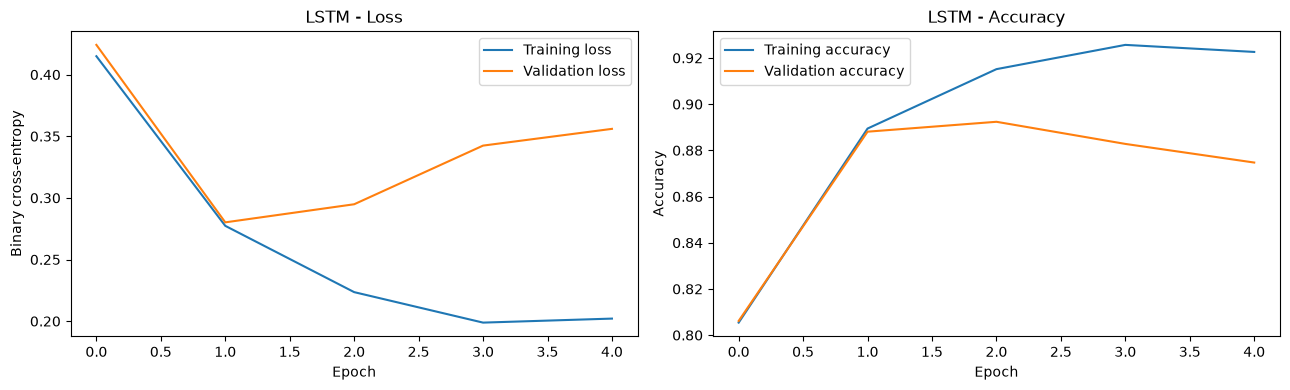

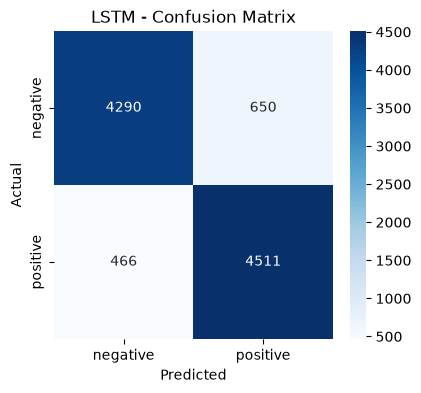

In [27]:
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(history_lstm.history['loss'], label='Training loss')
plt.plot(history_lstm.history['val_loss'], label='Validation loss')
plt.title('LSTM - Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_lstm.history['accuracy'], label='Training accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation accuracy')
plt.title('LSTM - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.savefig('plots/training_curves_lstm.png', dpi=150, bbox_inches='tight')
plt.show()

cm = confusion_matrix(y_test, pred_lstm)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.title('LSTM - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 5.6 Gradient flow comparison (LSTM vs SimpleRNN)

unrolled matches layer output: True


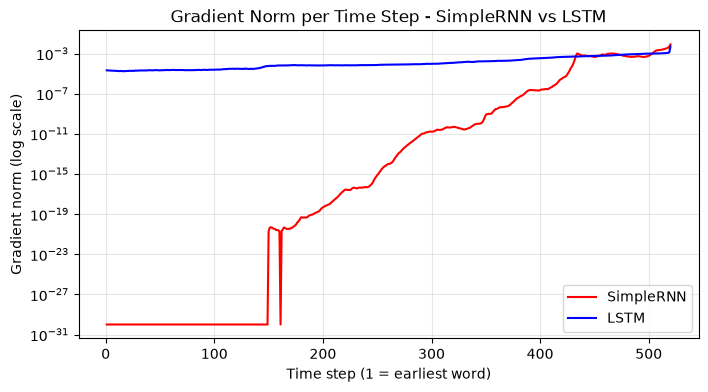

mean gradient norm over the first 10 steps -> SimpleRNN: 0.0 | LSTM: 1.9858559790009166e-05
the LSTM gradient at the earliest steps is about 1.99e+25 times larger


In [28]:
gn_lstm, ok = gradient_norms(model_lstm, X_batch, y_batch)
print('unrolled matches layer output:', ok)

plt.figure(figsize=(8, 4))
plt.semilogy(range(1, MAXLEN + 1), gn_rnn + 1e-30, color='red', label='SimpleRNN')
plt.semilogy(range(1, MAXLEN + 1), gn_lstm + 1e-30, color='blue', label='LSTM')
plt.title('Gradient Norm per Time Step - SimpleRNN vs LSTM')
plt.xlabel('Time step (1 = earliest word)')
plt.ylabel('Gradient norm (log scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('plots/gradient_norms_rnn_vs_lstm.png', dpi=150, bbox_inches='tight')
plt.show()

early = 10
ratio = gn_lstm[:early].mean() / (gn_rnn[:early].mean() + 1e-30)
print('mean gradient norm over the first', early, 'steps -> SimpleRNN:', gn_rnn[:early].mean(), '| LSTM:', gn_lstm[:early].mean())
print('the LSTM gradient at the earliest steps is about', '{:.3g}'.format(ratio), 'times larger')

## 5.7 Stacked LSTM

In [29]:
model_stack = build_model('stacked_lstm', units=64)
model_stack.summary()

timer_stack = EpochTimer()
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history_stack = model_stack.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.1, callbacks=[early_stop, timer_stack], verbose=1)
prob_stack, pred_stack = evaluate_model('Stacked LSTM', model_stack, history_stack, timer_stack)

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 520, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 520, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 119s 210ms/step - accuracy: 0.7611 - loss: 0.5018 - val_accuracy: 0.8543 - val_loss: 0.3523
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 117s 210ms/step - accuracy: 0.8824 - loss: 0.2935 - val_accuracy: 0.8835 - val_loss: 0.2955
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 142s 254ms/step - accuracy: 0.9124 - loss: 0.2336 - val_accuracy: 0.8714 - val_loss: 0.3049
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 126s 225ms/step - accuracy: 0.9162 - loss: 0.2194 - val_accuracy: 0.8790 - val_loss: 0.3353
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 123s 220ms/step - accuracy: 0.9215 - loss: 0.2093 - val_accuracy: 0.8851 - val_loss: 0.3387
Stacked LSTM -> {'Parameters': 357281, 'Time per Epoch (s)': 125.3, 'Epochs Trained': 5, 'Test Accuracy': 0.8858, 'Precision': 0.8662, 'Recall': 0.9134, 'F1': 0.8892, 'ROC-AUC': 0.9499}


# Task 6: GRU — Gated Recurrent Unit


## 6.2 GRU vs LSTM

| Property | LSTM | GRU |
|---|---|---|
| Number of gates | 3 (forget, input, output) | 2 (update, reset) |
| Separate cell state | Yes, `C(t)` and `h(t)` | No, only `h(t)` |
| Parameters (same hidden size) | 4 weight sets | 3 weight sets (about 3/4 of the LSTM) |
| Training speed | Slower | Faster |
| Typically preferred | Very long sequences, when the extra memory capacity matters | Smaller datasets, speed / memory limits, similar accuracy with less compute |

The GRU **merges the forget and input gates into one update gate**: one number `z` decides how much new information comes in and, at the same time, `1 − z` how much old information stays.

## 6.3 Parameter count by formula

In [30]:
gru_formula = 3 * (64 * 32 + 64 * 64 + 2 * 64)
print('formula 3 x (units x embedding_dim + units x units + 2 x units) = 3 x (2048 + 4096 + 128) =', gru_formula)
test_gru = GRU(64)
test_gru.build((None, MAXLEN, 32))
print('Keras GRU(64) parameters:', test_gru.count_params())
print('ratio to LSTM:', round(test_gru.count_params() / test_lstm.count_params(), 3))

formula 3 x (units x embedding_dim + units x units + 2 x units) = 3 x (2048 + 4096 + 128) = 18816
Keras GRU(64) parameters: 18816
ratio to LSTM: 0.758


## 6.4 Build, train and evaluate the GRU

In [31]:
model_gru = build_model('gru', units=64)
model_gru.summary()

timer_gru = EpochTimer()
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history_gru = model_gru.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.1, callbacks=[early_stop, timer_gru], verbose=1)
prob_gru, pred_gru = evaluate_model('GRU', model_gru, history_gru, timer_gru)
print(classification_report(y_test, pred_gru, target_names=['negative', 'positive']))

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ (None, 520, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 87s 153ms/step - accuracy: 0.7906 - loss: 0.4333 - val_accuracy: 0.8636 - val_loss: 0.3342
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 82s 147ms/step - accuracy: 0.8931 - loss: 0.2694 - val_accuracy: 0.8722 - val_loss: 0.3203
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 82s 147ms/step - accuracy: 0.9199 - loss: 0.2108 - val_accuracy: 0.8861 - val_loss: 0.2877
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 82s 147ms/step - accuracy: 0.9378 - loss: 0.1720 - val_accuracy: 0.8873 - val_loss: 0.2971
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 83s 149ms/step - accuracy: 0.9501 - loss: 0.1397 - val_accuracy: 0.8861 - val_loss: 0.3362
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 82s 147ms/step - accuracy: 0.9610 - loss: 0.1100 - val_accuracy: 0.8704 - val_loss: 0.3661
GRU -> {'Parameters': 338881, 'Time per Epoch (s)': 83.0, 'Epochs Trained': 6, 'Test Accuracy': 0.8885, 'Precision': 0.9185, 'Recall': 0.8535, 'F1': 0.8848, 'ROC-AUC': 0.9579}
              precision    recall  f1-

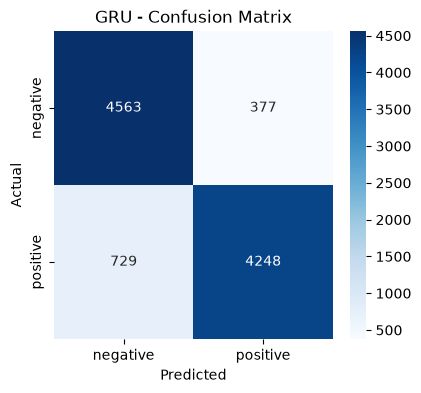

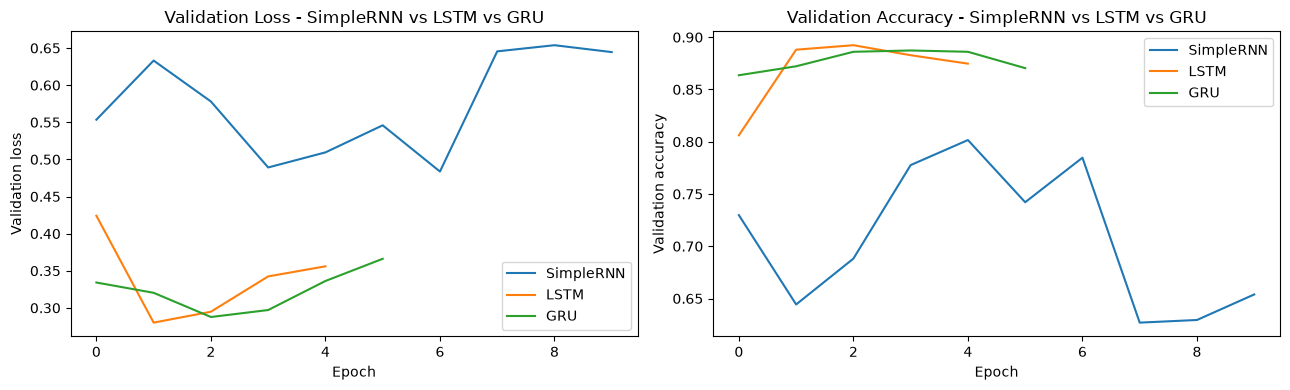

In [32]:
cm = confusion_matrix(y_test, pred_gru)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.title('GRU - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# training curves of the three cells together
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(history_rnn.history['val_loss'], label='SimpleRNN')
plt.plot(history_lstm.history['val_loss'], label='LSTM')
plt.plot(history_gru.history['val_loss'], label='GRU')
plt.title('Validation Loss - SimpleRNN vs LSTM vs GRU')
plt.xlabel('Epoch')
plt.ylabel('Validation loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_rnn.history['val_accuracy'], label='SimpleRNN')
plt.plot(history_lstm.history['val_accuracy'], label='LSTM')
plt.plot(history_gru.history['val_accuracy'], label='GRU')
plt.title('Validation Accuracy - SimpleRNN vs LSTM vs GRU')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.legend()
plt.tight_layout()
plt.savefig('plots/training_curves_rnn_lstm_gru.png', dpi=150, bbox_inches='tight')
plt.show()

## 6.5 Gradient flow — all three cells

unrolled matches layer output: True


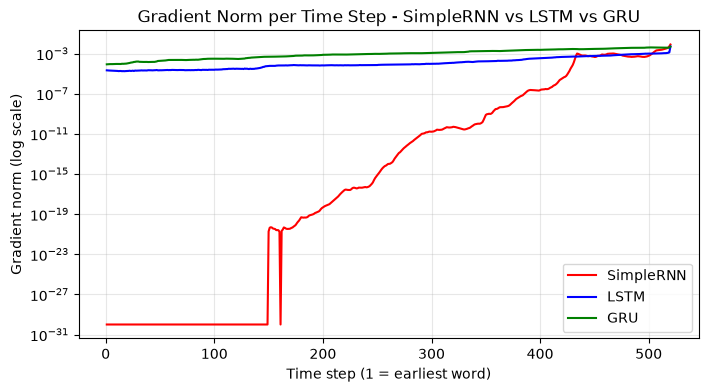

mean gradient norm over the first 10 steps: {'SimpleRNN': np.float64(0.0), 'LSTM': np.float64(1.9858559790009166e-05), 'GRU': np.float64(8.903799098334276e-05)}
ranking (best gradient flow first): ['GRU', 'LSTM', 'SimpleRNN']


In [33]:
gn_gru, ok = gradient_norms(model_gru, X_batch, y_batch)
print('unrolled matches layer output:', ok)

plt.figure(figsize=(8, 4))
plt.semilogy(range(1, MAXLEN + 1), gn_rnn + 1e-30, color='red', label='SimpleRNN')
plt.semilogy(range(1, MAXLEN + 1), gn_lstm + 1e-30, color='blue', label='LSTM')
plt.semilogy(range(1, MAXLEN + 1), gn_gru + 1e-30, color='green', label='GRU')
plt.title('Gradient Norm per Time Step - SimpleRNN vs LSTM vs GRU')
plt.xlabel('Time step (1 = earliest word)')
plt.ylabel('Gradient norm (log scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('plots/gradient_norms_all_cells.png', dpi=150, bbox_inches='tight')
plt.show()

early_means = {'SimpleRNN': gn_rnn[:10].mean(), 'LSTM': gn_lstm[:10].mean(), 'GRU': gn_gru[:10].mean()}
ranking = sorted(early_means, key=early_means.get, reverse=True)
print('mean gradient norm over the first 10 steps:', early_means)
print('ranking (best gradient flow first):', ranking)

## 6.6 Hidden-unit sensitivity

LSTM units 32 -> accuracy 0.8749 | parameters 328353
LSTM units 64 -> accuracy 0.8743 | parameters 344897
LSTM units 128 -> accuracy 0.7465 | parameters 402561
GRU units 32 -> accuracy 0.8847 | parameters 326369
GRU units 64 -> accuracy 0.8726 | parameters 338881
GRU units 128 -> accuracy 0.8803 | parameters 382337


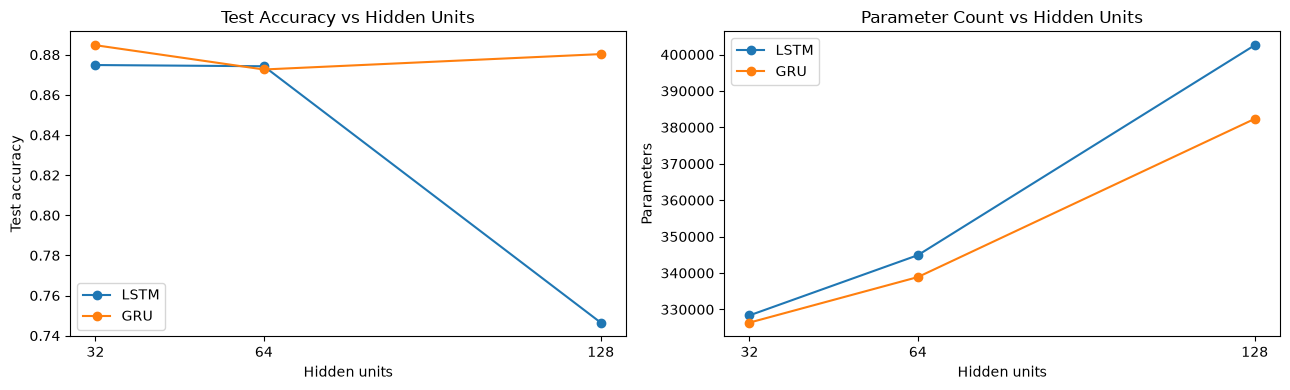

In [36]:
unit_list = [32, 64, 128]
sens = {'LSTM': {'acc': [], 'params': []}, 'GRU': {'acc': [], 'params': []}}

for cell in ['lstm', 'gru']:
    for u in unit_list:
        m = build_model(cell, units=u)
        m.fit(X_train, y_train, epochs=6, batch_size=64, validation_split=0.1, verbose=0)
        loss, acc = m.evaluate(X_test, y_test, verbose=0)
        sens[cell.upper()]['acc'].append(acc)
        sens[cell.upper()]['params'].append(m.count_params())
        print(cell.upper(), 'units', u, '-> accuracy', round(acc, 4), '| parameters', m.count_params())

plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(unit_list, sens['LSTM']['acc'], marker='o', label='LSTM')
plt.plot(unit_list, sens['GRU']['acc'], marker='o', label='GRU')
plt.title('Test Accuracy vs Hidden Units')
plt.xlabel('Hidden units')
plt.ylabel('Test accuracy')
plt.xticks(unit_list)
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(unit_list, sens['LSTM']['params'], marker='o', label='LSTM')
plt.plot(unit_list, sens['GRU']['params'], marker='o', label='GRU')
plt.title('Parameter Count vs Hidden Units')
plt.xlabel('Hidden units')
plt.ylabel('Parameters')
plt.xticks(unit_list)
plt.legend()
plt.tight_layout()
plt.savefig('plots/hidden_unit_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

# Task 7: Final Comparison, Inference & Recommendation

## 7.1 Full results table

In [44]:
order = ['ANN baseline', 'SimpleRNN', 'LSTM', 'Stacked LSTM', 'GRU']
rows = []
for name in order:
    r = results[name]
    rows.append([name, r['Parameters'], r['Time per Epoch (s)'], r['Epochs Trained'], r['Test Accuracy'], r['Precision'], r['Recall'], r['F1'], r['ROC-AUC']])
results_df = pd.DataFrame(rows, columns=['Model', 'Parameters', 'Time per Epoch (s)', 'Epochs Trained', 'Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'])

metric_cols = ['Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
display(results_df.style.highlight_max(subset=metric_cols, color='#ffcccc').format({'Parameters': '{:,}'}))

results_df.to_csv('plots/results_table.csv', index=False)


,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN baseline,"1,385,089",7.400000,5,0.862900,0.864500,0.861800,0.863200,0.935800
1,SimpleRNN,"326,273",47.400000,10,0.795000,0.786800,0.811300,0.798900,0.866100
2,LSTM,"344,897",70.000000,5,0.887500,0.874100,0.906400,0.889900,0.952000
3,Stacked LSTM,"357,281",125.300000,5,0.885800,0.866200,0.913400,0.889200,0.949900
4,GRU,"338,881",83.000000,6,0.888500,0.918500,0.853500,0.884800,0.957900


## 7.2 ROC curves

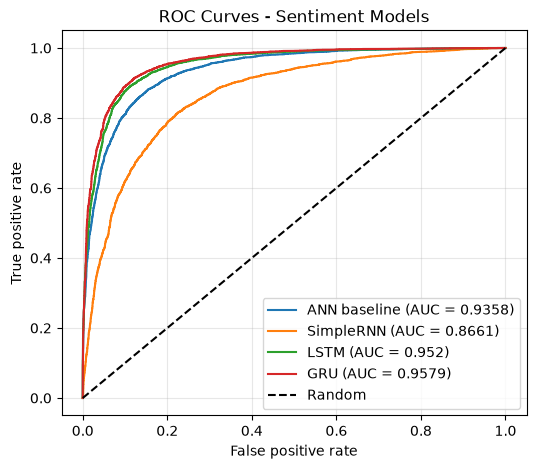

In [38]:
plt.figure(figsize=(6, 5))
for name in ['ANN baseline', 'SimpleRNN', 'LSTM', 'GRU']:
    fpr, tpr, thr = roc_curve(y_test, results[name]['prob'])
    plt.plot(fpr, tpr, label=name + ' (AUC = ' + str(results[name]['ROC-AUC']) + ')')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.title('ROC Curves - Sentiment Models')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('plots/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 7.3 Sequence-length robustness

best gated model by test accuracy: GRU
Short (<100) -> 1261 reviews
Medium (100-250) -> 5797 reviews
Long (>250) -> 2859 reviews
{'SimpleRNN': [0.8144329896907216, 0.8038640676211833, 0.7684505071703392], 'GRU': [0.8897700237906423, 0.8925306192858375, 0.8796782091640434]}


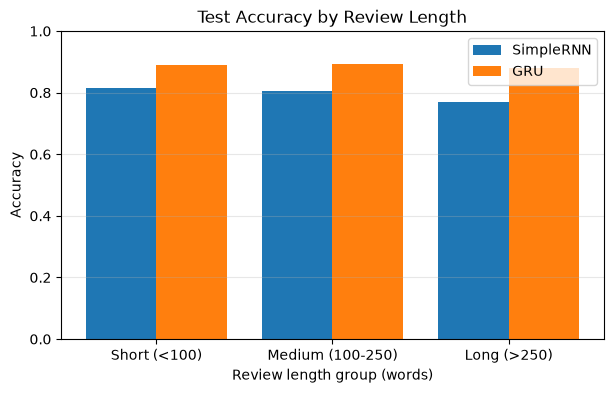

In [39]:
best_name = 'LSTM'
if results['GRU']['Test Accuracy'] > results['LSTM']['Test Accuracy']:
    best_name = 'GRU'
print('best gated model by test accuracy:', best_name)

test_words = np.array([len(t.split()) for t in X_test_text])
groups = {'Short (<100)': test_words < 100, 'Medium (100-250)': (test_words >= 100) & (test_words <= 250), 'Long (>250)': test_words > 250}

compare = ['SimpleRNN', best_name]
acc_len = {}
for name in compare:
    acc_len[name] = []
    pred = (results[name]['prob'] > 0.5).astype(int)
    for g in groups:
        mask = groups[g]
        acc_len[name].append(accuracy_score(y_test[mask], pred[mask]))
for g in groups:
    print(g, '->', int(groups[g].sum()), 'reviews')
print(acc_len)

x = np.arange(len(groups))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, acc_len['SimpleRNN'], width=0.4, label='SimpleRNN')
plt.bar(x + 0.2, acc_len[best_name], width=0.4, label=best_name)
plt.xticks(x, list(groups.keys()))
plt.ylim(0, 1)
plt.title('Test Accuracy by Review Length')
plt.xlabel('Review length group (words)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.savefig('plots/accuracy_by_length.png', dpi=150, bbox_inches='tight')
plt.show()

## 7.4 Error analysis

In [40]:
best_prob = results[best_name]['prob']
best_pred = (best_prob > 0.5).astype(int)

false_pos = np.where((best_pred == 1) & (y_test == 0))[0]
false_neg = np.where((best_pred == 0) & (y_test == 1))[0]
# most confident mistakes first
false_pos = false_pos[np.argsort(-best_prob[false_pos])][:4]
false_neg = false_neg[np.argsort(best_prob[false_neg])][:4]

print('Model:', best_name)
for kind, idx_list in [('FALSE POSITIVE (true = negative)', false_pos), ('FALSE NEGATIVE (true = positive)', false_neg)]:
    print('=' * 100)
    print(kind)
    for idx in idx_list:
        true_label = 'positive' if y_test[idx] == 1 else 'negative'
        print('true:', true_label, '| predicted probability of positive:', round(float(best_prob[idx]), 3), '| words:', test_words[idx])
        print(X_test_text[idx][:400], '...')
        print('-' * 100)

Model: GRU
FALSE POSITIVE (true = negative)
true: negative | predicted probability of positive: 0.993 | words: 108
back in the 's when i had first seen this i was in high school it was cool then now as an adult i look back at it and i say to myself yeah right what was so funny it has it's moments but they are few and far between it is so dated that the jokes no longer stand up show this to a younger crowd and they will be totally lost if you like this type of humor you may want to stick with kentucky fried mov ...
----------------------------------------------------------------------------------------------------
true: negative | predicted probability of positive: 0.991 | words: 125
i am a longtime fan of the original of this movie bella martha mostly martha and everything that makes that movie great and enjoyable to watch is missing from this one i miss the slow pace the build up of characters and their style in small gestures the dominance of lights and moods and moves over dialog i 

## 7.5 Inference function

In [41]:
best_model = models[best_name]

def predict_sentiment(text):
    cleaned = clean_text(text)                                   # same cleaning as training
    seq = tokenizer.texts_to_sequences([cleaned])                # same tokenizer as training
    padded = pad_sequences(seq, maxlen=MAXLEN, padding='pre', truncating='pre')   # same padding
    prob = float(best_model.predict(padded, verbose=0)[0][0])
    if prob > 0.5:
        label = 'positive'
    else:
        label = 'negative'
    return label, prob

tests = [
    ('This movie was absolutely wonderful, the acting and the story were brilliant.', 'positive', 'clearly positive'),
    ('This was the worst film I have ever seen, a boring and terrible waste of time.', 'negative', 'clearly negative'),
    ('This film is not good.', 'negative', 'negation'),
    ('I cannot say that this film is not worth watching, it was not bad at all.', 'positive', 'double negation'),
    ('Oh great, another two hours of my life wasted. What a masterpiece of boredom.', 'negative', 'sarcastic'),
    ('Great.', 'positive', 'very short'),
    ('The plot was predictable but the soundtrack and the performances made it enjoyable.', 'positive', 'mixed')
]

rows = []
for text, expected, kind in tests:
    label, prob = predict_sentiment(text)
    rows.append([kind, text[:60] + '...', expected, label, round(prob, 3), 'Yes' if label == expected else 'No'])
infer_df = pd.DataFrame(rows, columns=['Type', 'Sentence', 'Expected', 'Predicted', 'P(positive)', 'Match'])
display(infer_df)

,Type,Sentence,Expected,Predicted,P(positive),Match
0,clearly positive,"This movie was absolutely wonderful, the actin...",positive,positive,0.981,Yes
1,clearly negative,"This was the worst film I have ever seen, a bo...",negative,negative,0.001,Yes
2,negation,This film is not good....,negative,positive,0.920,No
3,double negation,I cannot say that this film is not worth watch...,positive,negative,0.157,No
4,sarcastic,"Oh great, another two hours of my life wasted....",negative,negative,0.121,Yes
5,very short,Great....,positive,positive,1.000,Yes
6,mixed,The plot was predictable but the soundtrack an...,positive,positive,0.686,Yes


## 7.6 Which Recurrent Cell Should We Use?

In [42]:
metric_rank = results_df.set_index('Model')
rnn_models = ['SimpleRNN', 'LSTM', 'Stacked LSTM', 'GRU']
sub = metric_rank.loc[rnn_models]

print('(a) Ranking by Test Accuracy:', list(sub['Test Accuracy'].sort_values(ascending=False).index))
print('    Ranking by F1           :', list(sub['F1'].sort_values(ascending=False).index))
print('    Ranking by ROC-AUC      :', list(sub['ROC-AUC'].sort_values(ascending=False).index))
print()
print('(b) Parameters / time per epoch (s):')
print(sub[['Parameters', 'Time per Epoch (s)']].to_string())
print()
print('(c) Accuracy on LONG reviews (>250 words):')
for name in compare:
    print('   ', name, round(acc_len[name][2], 4), '(short:', round(acc_len[name][0], 4), ')')
print()

gated = sub.loc[['LSTM', 'Stacked LSTM', 'GRU']]
best_f1 = gated['F1'].idxmax()
recommended = best_f1
if best_f1 != 'GRU' and (gated.loc[best_f1, 'F1'] - gated.loc['GRU', 'F1']) < 0.005:
    recommended = 'GRU'      # practically the same quality, fewer parameters and faster
print('(d) Final recommendation for a production sentiment service:', recommended)

(a) Ranking by Test Accuracy: ['GRU', 'LSTM', 'Stacked LSTM', 'SimpleRNN']
    Ranking by F1           : ['LSTM', 'Stacked LSTM', 'GRU', 'SimpleRNN']
    Ranking by ROC-AUC      : ['GRU', 'LSTM', 'Stacked LSTM', 'SimpleRNN']

(b) Parameters / time per epoch (s):
              Parameters  Time per Epoch (s)
Model                                       
SimpleRNN         326273                47.4
LSTM              344897                70.0
Stacked LSTM      357281               125.3
GRU               338881                83.0

(c) Accuracy on LONG reviews (>250 words):
    SimpleRNN 0.7685 (short: 0.8144 )
    GRU 0.8797 (short: 0.8898 )

(d) Final recommendation for a production sentiment service: LSTM
